# ISA 591 · Module 6 · Class 2
## Descriptive Logistic Regression — Airbnb Reservation Cancellations

**Interactive worksheet · ~80 minutes · `statsmodels`**

**Business case:** An Airbnb-style booking platform wants to understand which reservation and guest characteristics are **associated with guest-initiated cancellations before check-in**. The platform might use these findings to improve booking communication, support hosts, or evaluate reservation policies.

**Your task:** Fit and interpret a multiple logistic regression model. Focus on **coefficients, odds ratios, statistical significance, model fit, and predicted probabilities** rather than trying to maximize accuracy.

**Today's plan:** overview (10 min) → preparation (10) → fit (15) → odds ratios (20) → hypothesis tests (10) → probabilities (10) → discussion (5).

### 1. Load and explore the bookings

The CSV is included with the notebook. Open the notebook from the same folder as `ISA591_Airbnb_Bookings_2500.csv`.

- `cancelled = 1` means the guest cancelled before check-in; `0` means the stay was not cancelled by the guest.
- `lead_time` is the number of days between booking and check-in.
- `price_per_night` is USD per night; `nights` is the reserved length of stay.
- `flexible_policy`, `instant_book`, and `repeat_guest` are 0/1 indicators.
- `prior_cancellations` is the count of earlier cancellations by the guest on the platform.
- `host_rating` is the rating at booking time.
- `property_type`, `destination_type`, and `booking_month` are available for optional extensions.
- `total_price` is the synthetic total including illustrative fees and is deliberately left out of the main model because of redundancy with price and length of stay.
- `booking_id` is just an identifier; it must not be a predictor.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Keep this CSV in the same folder as the notebook.
df = pd.read_csv('https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/ISA591_Airbnb_Bookings_2500.csv')

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (2500, 14)


,booking_id,cancelled,lead_time,price_per_night,nights,total_price,flexible_policy,instant_book,repeat_guest,prior_cancellations,host_rating,property_type,destination_type,booking_month
0,BKG-100001,1,45,209.54,2,450.90,1,0,0,0,5.00,Entire home,Urban,8
1,BKG-100002,0,44,122.25,4,528.05,1,1,1,0,4.33,Private room,Urban,9
2,BKG-100003,0,22,82.36,4,390.32,0,1,0,0,5.00,Private room,Urban,7
3,BKG-100004,0,33,242.12,3,761.98,1,1,1,0,4.61,Entire home,Mountain,6
4,BKG-100005,1,98,173.37,4,759.26,1,0,1,2,5.00,Entire home,Urban,3


**Check:** Is this a balanced classification problem? Count the cancellations and calculate their percentage. The objective today is **descriptive association**: a variable may be associated with cancellation without causing it.

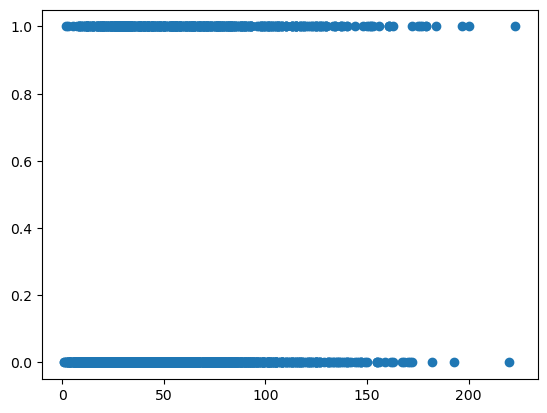

In [5]:
## CHECK FOR IMBALANCE
df.cancelled.value_counts() / len(df) ## consider imbalance modeling (SMOTE) if fraction is lower than 5%

## LEAD TIME (SCATTER OF LEAD TIME VS CANCELLED)
plt.scatter(df.lead_time, df.cancelled)

### 2. Quick visualization and missing values

Look at the distribution of `lead_time` and the frequency of cancellation. There are a few missing values in `host_rating` in cases with incomplete host histories. For this **descriptive classroom example** we use median imputation; for predictive evaluation, imputation should be learned from training data only.

<Axes: xlabel='cancelled', ylabel='lead_time'>

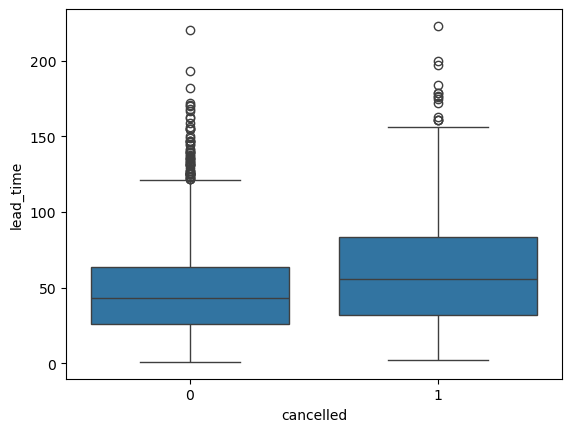

In [6]:
## Relationships 
import seaborn as sns

sns.boxplot(data = df, x = 'cancelled',  y = "lead_time")

In [8]:
## LOGISTIC REGRESSION 
#### outputs statistical relationships (p-vals)
#### y = {1: cancelled, 0: did not cancel} ------ P(CANCELLING)
import statsmodels.api as sm

## Create instance and fit
lr = sm.Logit(df.cancelled, sm.add_constant(df.lead_time)).fit()

## Summary
print(lr.summary())

Optimization terminated successfully.
         Current function value: 0.537007
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              cancelled   No. Observations:                 2500
Model:                          Logit   Df Residuals:                     2498
Method:                           MLE   Df Model:                            1
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.02797
Time:                        10:42:44   Log-Likelihood:                -1342.5
converged:                       True   LL-Null:                       -1381.1
Covariance Type:            nonrobust   LLR p-value:                 1.498e-18
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.7964      0.091    -19.716      0.000      -1.975      -1.618
lead_time      0.0118      0.

In [12]:
## yhat is Log(Odds) of Cancelling
#### Estimated Log Odds of Cancelling = -1.7964 + 0.0118*Lead Time

## e.g., say lead_time = 10 days
log_odds = -1.7964 + 0.0118*10
print(f'The Log(Odds) of Cancelling the AIRBNB with 10 days of Lead Time is: {log_odds}')

## suppose z = log_odds
## LINK: p = exp(z) / (1 + exp(z))
prob = np.exp(log_odds) / (1+np.exp(log_odds))
print(f'The Probability of Cancelling the AIRBNB with 10 days of Lead Time is: {prob}')

The Log(Odds) of Cancelling the AIRBNB with 10 days of Lead Time is: -1.6784
The Probability of Cancelling the AIRBNB with 10 days of Lead Time is: 0.1573074515159828


In [13]:
## INTERPRETATION OF THE SLOPE
#### As the lead time increases by 1 day, the LOG ODDS OF CANCELLING increases by 0.0118
#### As the lead time increases by 1 day, the ODDS OF CANCELLING increases by A FACTOR OF np.exp(0.0118) = 1.012

1.011869894648401

In [16]:
## STATISTICAL RELATIONSHIPS
b = 0.0118         ## estimated slope of lead time 
s_b = 0.001        ## std error of the estimated slope (how much variation)

## statistical distance between the estimate and 0:  (b - 0) / s_b
z = b / s_b        ## how many std errors is b away from 0  ------ z is distributed is NORMAL(mean = 0, std dev = 1) 
print(f'The number of std errors is the estimate away from zero is: {z}')

The number of std errors is the estimate away from zero is: 11.799999999999999


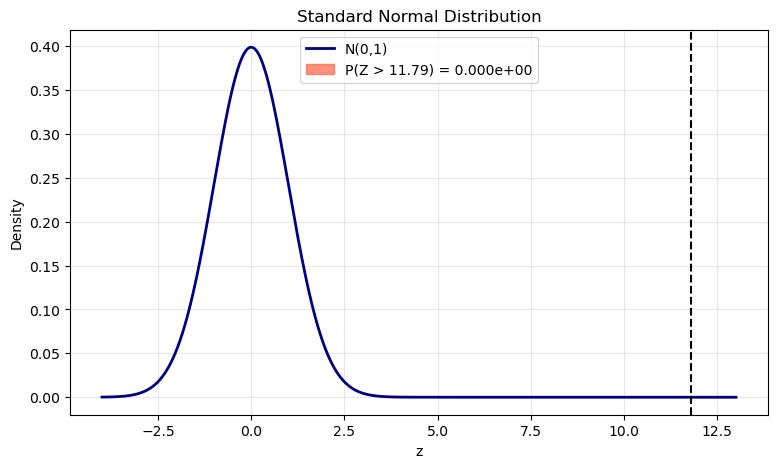

P(Z > 11.79) = 0.000e+00


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

z_value = 11.79

# Create x-grid for the standard normal distribution
x = np.linspace(-4, 13, 1000)
y = norm.pdf(x)

# Tail probability
p_tail = 1 - norm.cdf(z_value)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

# Standard normal curve
ax.plot(x, y, color='navy', lw=2, label='N(0,1)')

# Shade area to the right of z = 11.79
mask = x >= z_value
ax.fill_between(x[mask], y[mask], color='tomato', alpha=0.7,
                label=f'P(Z > {z_value}) = {p_tail:.3e}')

# Vertical line at z = 11.79
ax.axvline(z_value, color='black', linestyle='--', linewidth=1.5)

# Labels and title
ax.set_title('Standard Normal Distribution')
ax.set_xlabel('z')
ax.set_ylabel('Density')
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print(f"P(Z > {z_value}) = {p_tail:.3e}")

In [ ]:
## HYPOTHESIS TEST

## H0: B = 0  (no relationship)
## HA: B!= 0  (relationship)

## Reject H0 in favor of the alternative
#### There is enough evidence to say that lead time is related to the log odds of cancelling (prob of cancelling)

### 3. Define predictors and fit a multiple logistic model

We will use eight easy-to-interpret variables. Keeping numeric and 0/1 features avoids distracting from coefficient interpretation. We will use `sm.Logit()` and `sm.add_constant()` as in the course notes.

Notice that the response, identifiers, and unrelated extra columns are not included in `X`.

In [20]:
# Fill the few missing host ratings
# select only ['lead_time', 'price_per_night', 'nights', 'flexible_policy', 'instant_book', 'repeat_guest', 'prior_cancellations', 'host_rating']

## 1) fill the missing values of host rating with median
df.host_rating = df.host_rating.fillna(df.host_rating.median())

## 2) create X with only ['lead_time', 'price_per_night', 'nights', 'flexible_policy', 'instant_book', 'repeat_guest', 'prior_cancellations', 'host_rating']
X = df[['lead_time', 'price_per_night', 'nights', 'flexible_policy', 'instant_book', 'repeat_guest', 'prior_cancellations', 'host_rating']]

## 3) create y (cancelled)
y = df.cancelled


In [22]:
# Obtain the regression summary

## 4) Create instance of logistic regression and fit
lr = sm.Logit(y, sm.add_constant(X)).fit()

## 5) get the summary
print(lr.summary())

Optimization terminated successfully.
         Current function value: 0.511018
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              cancelled   No. Observations:                 2500
Model:                          Logit   Df Residuals:                     2491
Method:                           MLE   Df Model:                            8
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.07501
Time:                        11:14:27   Log-Likelihood:                -1277.5
converged:                       True   LL-Null:                       -1381.1
Covariance Type:            nonrobust   LLR p-value:                 1.933e-40
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -0.1499      0.882     -0.170      0.865      -1.878       1.578
le

In [ ]:
## what does nights being NOT SIGNIFICANT mean?
#### in the presence of the other vars, nights DOES NOT CONTRIBUTE statistically to understanding the log odds of cancelling

## should you drop nights from the model?
#### ideally, you would keep ONLY significant variables in a DESCRIPTIVE model


In [ ]:
## LLR Test
## OVERALL TEST OF SIGNIFICANCE
#### H0: B1 = B2 = ... = 0
#### HA: At least one is NOT

#### P-VAL
#### probability that we get an LLR as extreme as it is, given that H0 is true
#### p-val = 1.933e-40 = 0
#### we reject H0 and conclude that at least 1 variable is important

**Read the output:** Find the `coef`, `P>|z|`, `LLR p-value`, `Pseudo R-squ.`, and `converged` fields. Which predictors have evidence of an association at a 5% significance level? Which do not?

**Important:** A coefficient measures a change in **log-odds**, holding the other variables in this model constant. A significant association does not prove causation.

### 4. Interpret coefficients and odds ratios (35–55 min)

The odds ratio is `exp(coefficient)`. If the odds ratio is above 1, the estimated odds increase; below 1, they decrease, **holding other variables constant**.

One day or one dollar is a small unit. For easier interpretation, we can calculate the effect of **10 additional lead-time days** or **$50 more per night** without refitting the model.

In [ ]:
results = pd.DataFrame({
    'Coefficient': log_reg.params,
    'Odds Ratio (1 unit)': np.exp(log_reg.params),
    'p-value': log_reg.pvalues
})
display(results.round(4))

print('Odds ratio for +10 lead-time days:',
      round(np.exp(10 * log_reg.params['lead_time']), 3))
print('Odds ratio for +$50 per night:',
      round(np.exp(50 * log_reg.params['price_per_night']), 3))
print('Odds ratio for flexible vs nonflexible policy:',
      round(np.exp(log_reg.params['flexible_policy']), 3))
print('Odds ratio for repeat vs first-time guest:',
      round(np.exp(log_reg.params['repeat_guest']), 3))

,Coefficient,Odds Ratio (1 unit),p-value
const,-0.1499,0.8608,0.8650
lead_time,0.0132,1.0133,0.0000
price_per_night,0.0026,1.0026,0.0000
nights,0.0194,1.0196,0.4783
flexible_policy,0.6568,1.9286,0.0000
instant_book,0.0226,1.0229,0.8209
repeat_guest,-0.5107,0.6001,0.0000
prior_cancellations,0.6821,1.9781,0.0000
host_rating,-0.5665,0.5675,0.0024


Odds ratio for +10 lead-time days: 1.141
Odds ratio for +$50 per night: 1.14
Odds ratio for flexible vs nonflexible policy: 1.929
Odds ratio for repeat vs first-time guest: 0.6


**TODO — In your own words:**

1. Interpret the odds ratio for 10 additional days of `lead_time`.
2. Interpret `flexible_policy = 1` compared with `0`.
3. Which is different: *odds increase by 20%* versus *cancellation probability increases by 20 percentage points*? Explain why.
4. Why might a flexible policy be **associated** with more cancellations without necessarily **causing** them?

### 5. Hypothesis tests and model fit (55–65 min)

For each predictor, the usual two-sided test is $H_0: \beta_j = 0$ versus $H_A: \beta_j \neq 0$. The `LLR p-value` tests the fitted model against an intercept-only model (all slopes equal zero). `Pseudo R-squ.` is **not** the same as the ordinary linear-regression $R^2$.

A 95% confidence interval for an odds ratio can be obtained by exponentiating the coefficient confidence interval.

### 6. Predicted probabilities: three booking profiles (65–75 min)

Consider these **hypothetical** bookings. Their characteristics are known when the reservation is confirmed. Compare their estimated cancellation probabilities.

This is a descriptive model, so these are illustrations of fitted associations—not verified forecasts or rules for guest treatment.

In [ ]:
bookings = pd.DataFrame({
    'lead_time': [90, 7, 45],
    'price_per_night': [250, 120, 180],
    'nights': [5, 3, 4],
    'flexible_policy': [1, 0, 1],
    'instant_book': [0, 1, 1],
    'repeat_guest': [0, 1, 0],
    'prior_cancellations': [2, 0, 1],
    'host_rating': [4.5, 4.9, 4.7]
}, index=['Booking A', 'Booking B', 'Booking C'])

bookings['prob_cancel'] = log_reg.predict(
    sm.add_constant(bookings, has_constant='add')
)
display(bookings.round(3))

**TODO:** Change Booking A's `lead_time` from 90 to 30 days, rerun, and compare its predicted probability. Explain why the **change in probability** is not equal to its **odds ratio**.

In [ ]:
# Example: convert the model's linear score for Booking B to a probability.
booking_b = bookings.loc['Booking B', X.columns]
log_odds = log_reg.params['const'] + np.dot(
    booking_b, log_reg.params[X.columns]
)
odds = np.exp(log_odds)
probability = odds / (1 + odds)

print('Booking B log-odds:', round(log_odds, 3))
print('Booking B odds:', round(odds, 3))
print('Booking B probability:', round(probability, 3))

### 7. Interpret the results for management (75–80 min)

**Exit ticket:** Write 2–3 sentences answering these questions:

1. Which two predictors appear most relevant to *understanding* cancellations in this sample? Use coefficients, uncertainty, and units to justify your choice.
2. What would you tell Airbnb's analytics team **not** to conclude from these associations?
3. What additional evidence would you want before changing a cancellation policy?

**Optional extension:** `property_type` is categorical. Encode it using the same simple approach from earlier modules, then refit:

```python
property_dummies = pd.get_dummies(df['property_type'], drop_first=True).astype(int)
X_more = pd.concat([X, property_dummies], axis=1)
model_more = sm.Logit(y, sm.add_constant(X_more)).fit()
print(model_more.summary())
```

If you include category indicators, interpret them relative to the omitted reference category. **Do not include `total_price` alongside both `price_per_night` and `nights` without considering redundancy.**